# Weather Forecasting — Exploratory Data Analysis

Single EDA notebook for the project, scoped to the **7 modeled targets**
`temp, rh, dew, pressure, cloud, wx, wy`. `wx`/`wy` are the Cartesian wind
components engineered from `wind_speed_10m` / `wind_direction_10m`; other raw
columns in the CSV are not modeled and are not analyzed here.

**Part A — Overview:** distributions, series, correlation, wind, outliers.
**Part B — Time-series diagnostics (course-aligned):** stationarity (ADF+KPSS),
ACF/PACF, decomposition, lagged cross-correlation — the evidence behind the VAR
design choices.

In [1]:
import math
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller, kpss, ccf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose

sns.set_theme(style="whitegrid")


def clean_names(df):
    pref = {
        "temperature_2m": "temp", "relative_humidity_2m": "rh",
        "dew_point_2m": "dew", "surface_pressure": "pressure",
        "cloud_cover": "cloud", "wind_speed_10m": "wind_speed",
        "wind_direction_10m": "wind_dir",
    }
    return df.rename(columns={c: pref.get(c.split(" (")[0].strip(), c) for c in df.columns})


# Load + clean (data is already hourly)
raw = pd.read_csv("data/weather_dataset.csv")
raw["time"] = pd.to_datetime(raw["time"])
raw = raw.set_index("time").sort_index().asfreq("h")
raw = clean_names(raw)

# Wind decomposition: circular (speed, direction) -> Cartesian (wx, wy).
rad = np.radians(raw["wind_dir"])
raw["wx"] = raw["wind_speed"] * np.cos(rad)
raw["wy"] = raw["wind_speed"] * np.sin(rad)

TARGETS = ["temp", "rh", "dew", "pressure", "cloud", "wx", "wy"]
data = raw[TARGETS].dropna()          # hourly, 7 targets
daily = data.resample("D").mean()     # daily-resampled
print("hourly shape:", data.shape, " | daily shape:", daily.shape)
data.head()

hourly shape: (43824, 7)  | daily shape: (1826, 7)


,temp,rh,dew,pressure,cloud,wx,wy
time,,,,,,,
2021-01-01 00:00:00,9.4,49,-0.8,1025.7,0,6.881012,4.641301
2021-01-01 01:00:00,9.1,50,-0.7,1025.4,0,7.505055,3.990508
2021-01-01 02:00:00,8.8,51,-0.8,1025.0,0,8.284544,3.516580
2021-01-01 03:00:00,8.6,50,-1.3,1024.7,11,9.735430,3.933369
2021-01-01 04:00:00,8.5,50,-1.5,1025.0,46,10.477178,4.233055


# Part A — Overview

## Data summary

In [2]:
print("Shape:", data.shape)
data.info()

Shape: (43824, 7)
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 43824 entries, 2021-01-01 00:00:00 to 2025-12-31 23:00:00
Freq: h
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   temp      43824 non-null  float64
 1   rh        43824 non-null  int64  
 2   dew       43824 non-null  float64
 3   pressure  43824 non-null  float64
 4   cloud     43824 non-null  int64  
 5   wx        43824 non-null  float64
 6   wy        43824 non-null  float64
dtypes: float64(5), int64(2)
memory usage: 2.7 MB


In [3]:
data.describe()

,temp,rh,dew,pressure,cloud,wx,wy
count,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,4.382400e+04,43824.000000
mean,24.012509,78.750799,19.805844,1009.674304,73.412696,2.759876e-01,3.833834
std,5.562231,14.855629,6.363391,7.411169,37.257823,8.158420e+00,4.658065
min,6.300000,22.000000,-8.900000,982.000000,0.000000,-2.269245e+01,-36.691512
25%,20.200000,69.000000,15.600000,1003.600000,43.000000,-6.042513e+00,1.419566
50%,24.900000,81.000000,22.100000,1009.300000,99.000000,1.959435e-16,4.252978
75%,27.900000,92.000000,25.000000,1015.400000,100.000000,5.977168e+00,6.811736
max,39.000000,100.000000,28.800000,1032.900000,100.000000,5.722886e+01,45.015897


In [4]:
# Null check
data.isnull().sum()

temp        0
rh          0
dew         0
pressure    0
cloud       0
wx          0
wy          0
dtype: int64

## Distributions of the 7 targets

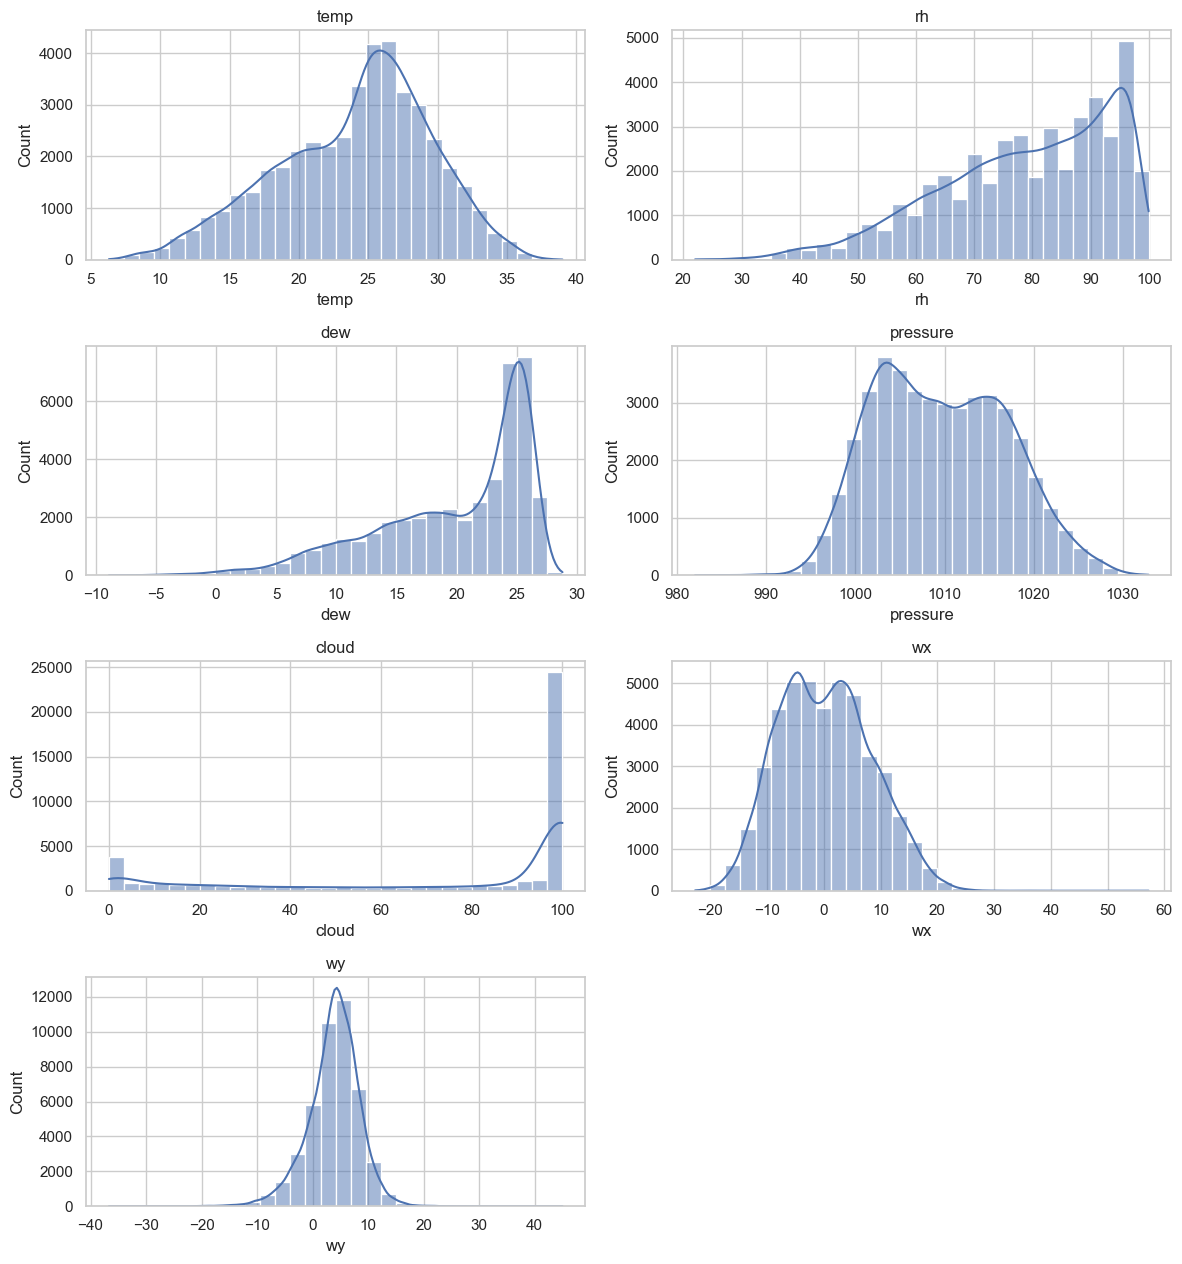

In [5]:
n_cols = 2
n_rows = math.ceil(len(TARGETS) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3.2 * n_rows))
axes = axes.flatten()
for i, col in enumerate(TARGETS):
    sns.histplot(data[col].dropna(), bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

## Weekly-averaged series over time (trend + seasonality)

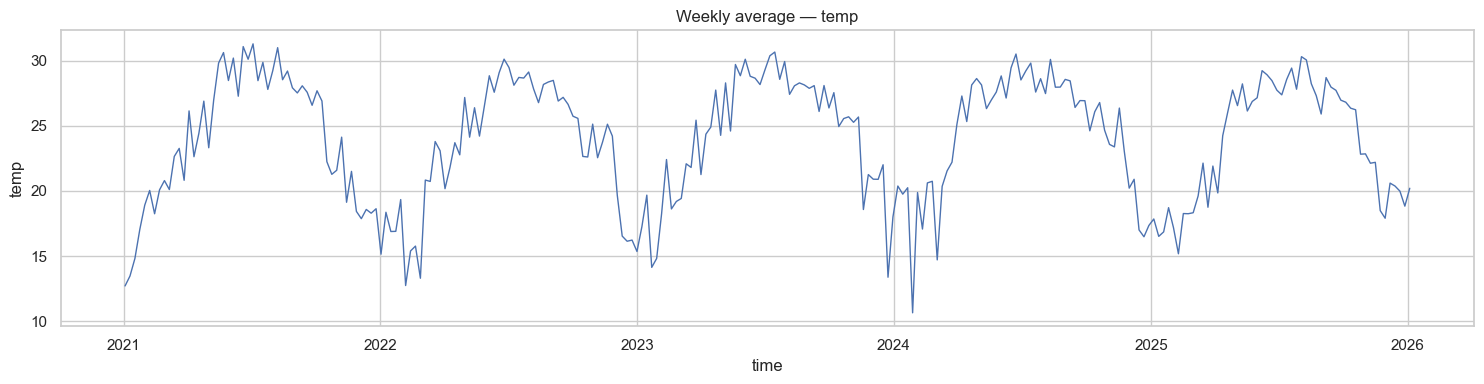

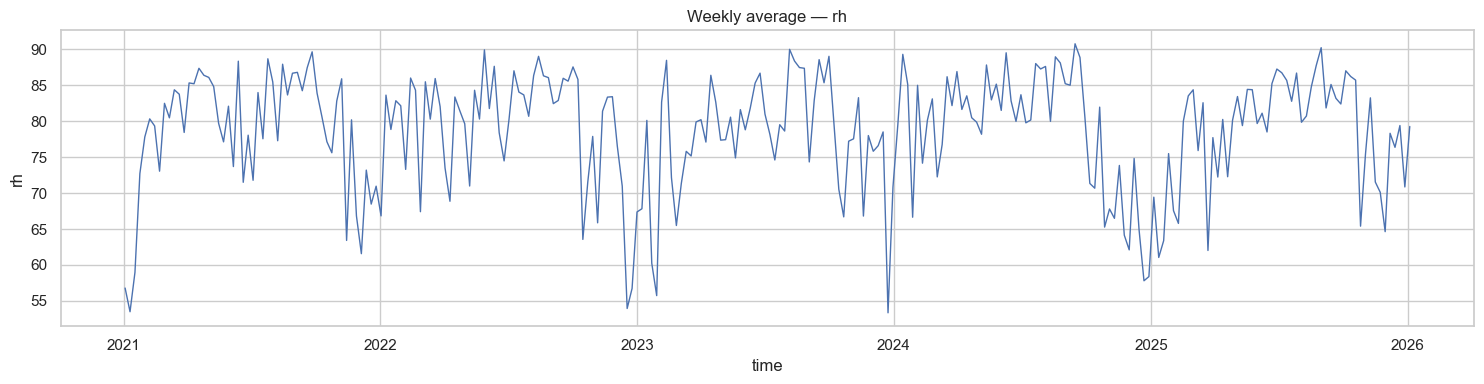

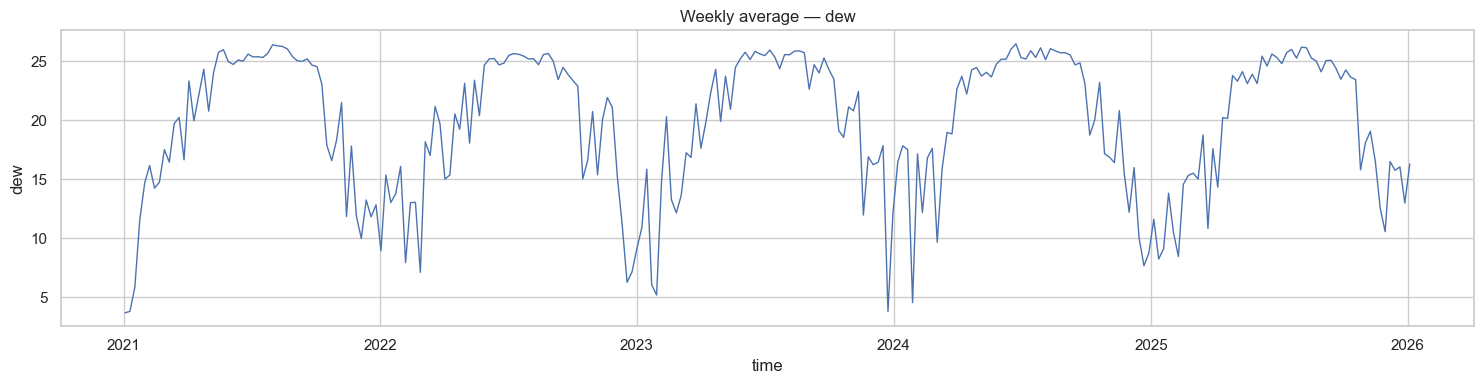

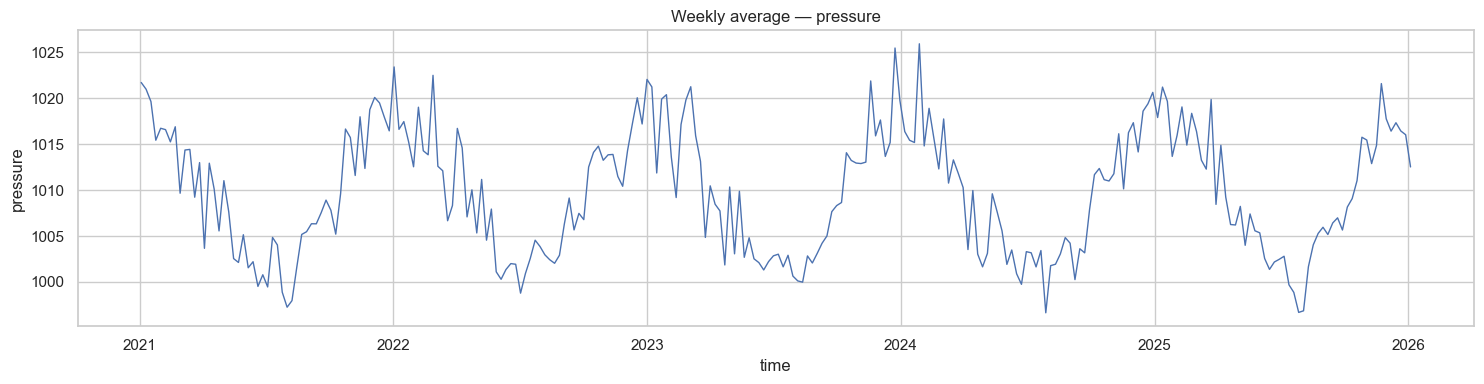

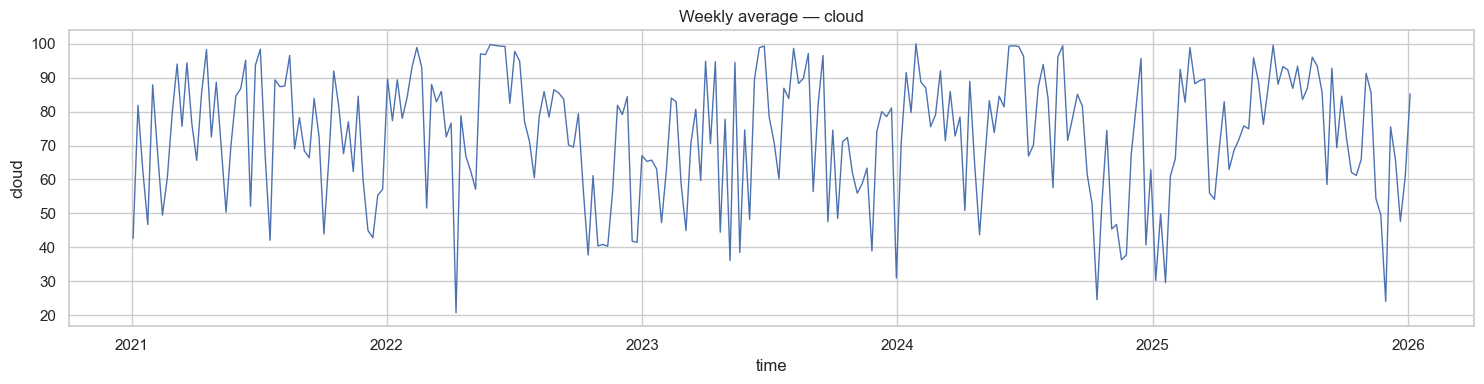

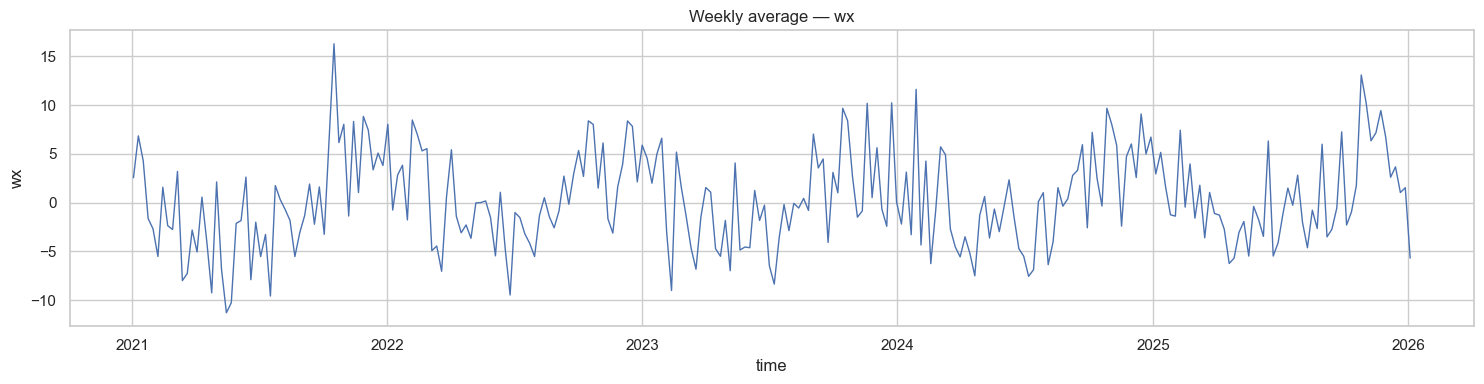

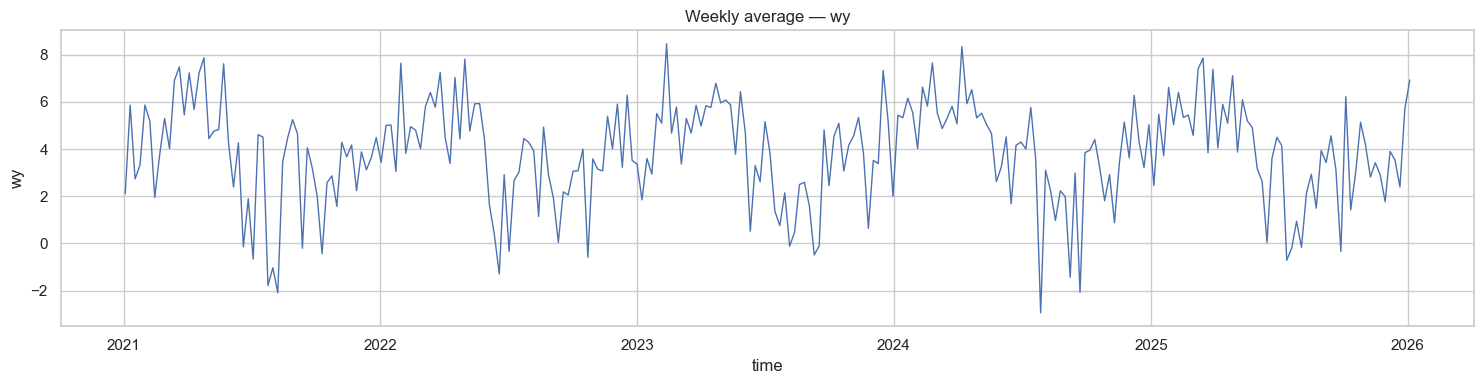

In [6]:
for col in TARGETS:
    weekly = data[col].resample("W").mean()
    plt.figure(figsize=(15, 4))
    sns.lineplot(x=weekly.index, y=weekly.values, linewidth=1)
    plt.title(f"Weekly average — {col}")
    plt.xlabel("time"); plt.ylabel(col)
    plt.tight_layout()
    plt.show()

## Correlation heatmap (7 targets)

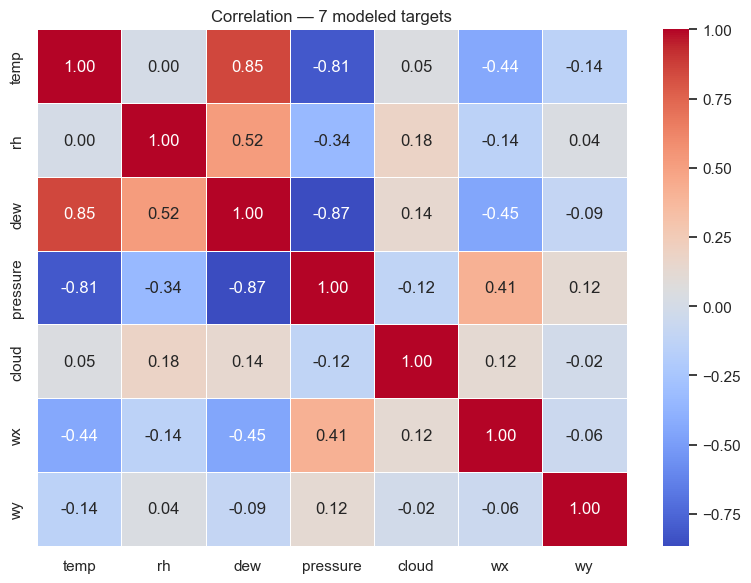

In [7]:
plt.figure(figsize=(8, 6))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation — 7 modeled targets")
plt.tight_layout()
plt.show()

## Wind rose — the modeled wind (wx, wy in polar form)

`wx`/`wy` are `wind_speed`/`wind_dir` in Cartesian form, so the wind rose is the
natural EDA view of the two wind targets.

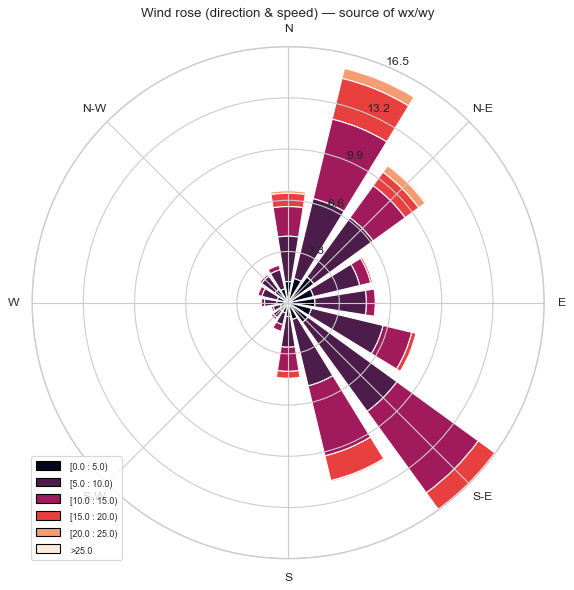

In [8]:
try:
    from windrose import WindroseAxes
    ax = WindroseAxes.from_ax()
    ax.bar(raw["wind_dir"], raw["wind_speed"], normed=True, opening=0.8,
           edgecolor="white", bins=np.arange(0, 30, 5))
    ax.set_title("Wind rose (direction & speed) — source of wx/wy")
    ax.set_legend()
    plt.show()
except ImportError:
    print("windrose not installed; skipping (pip install windrose).")

## Boxplots — spread and outliers (7 targets)

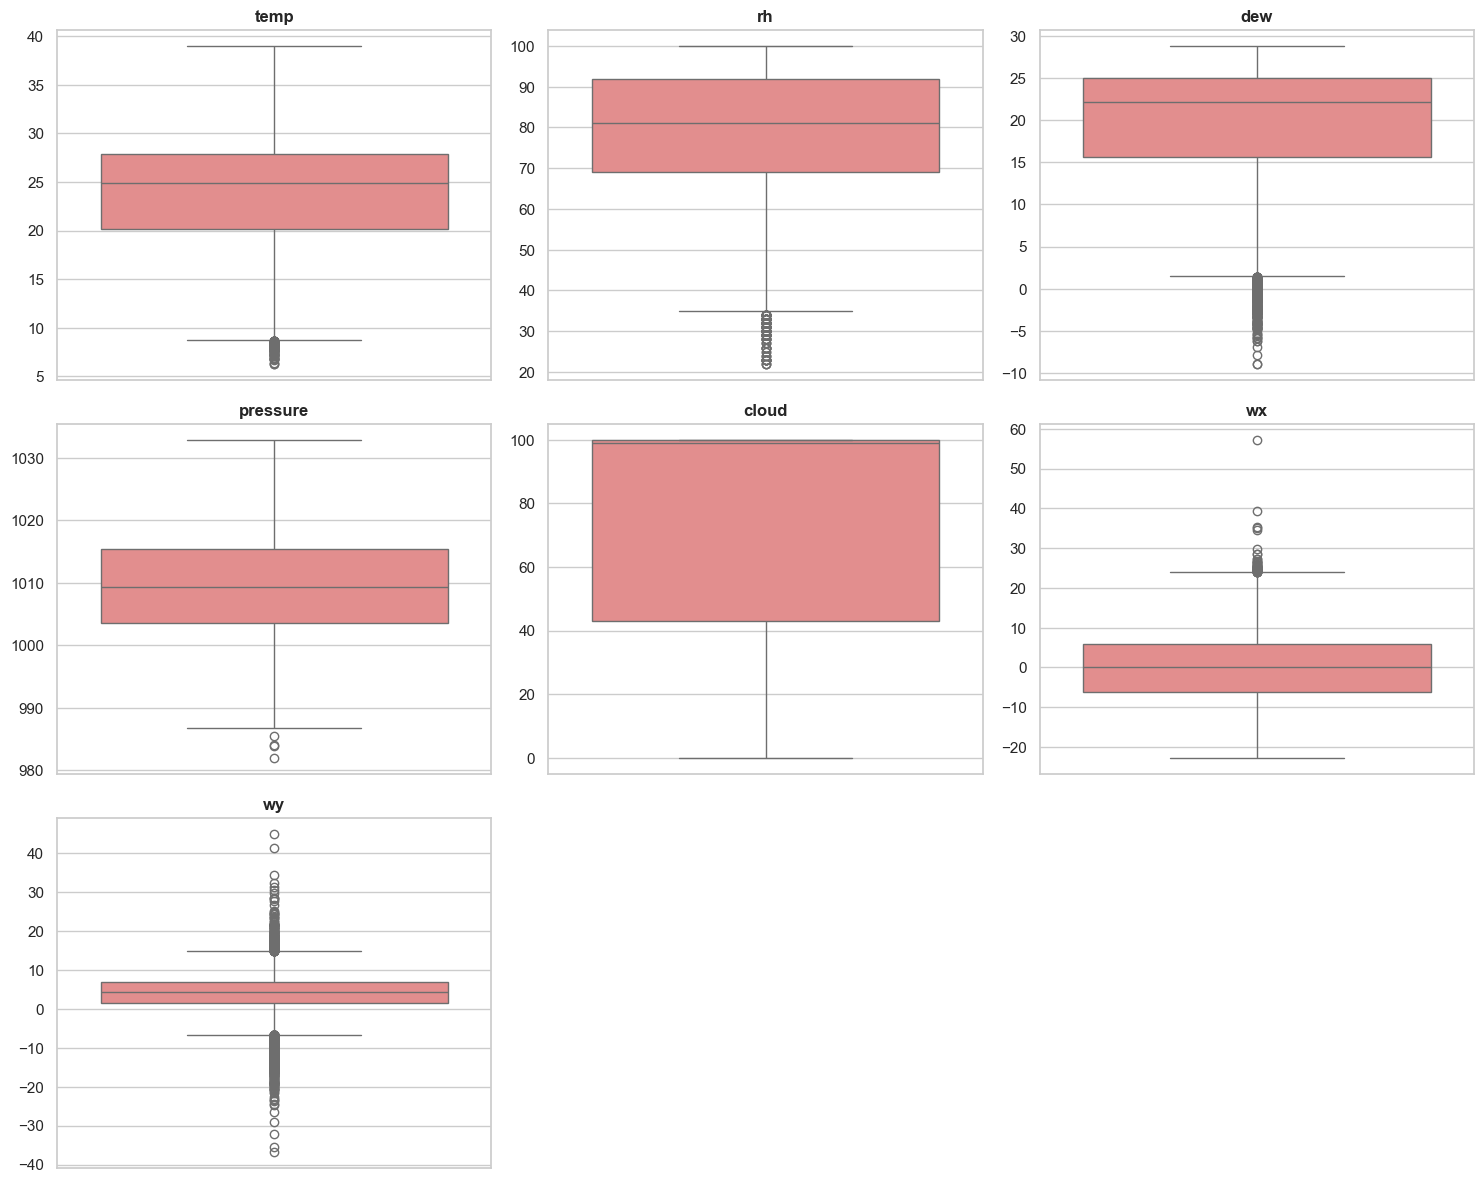

In [9]:
cols_per_row = 3
rows = math.ceil(len(TARGETS) / cols_per_row)
fig, axes = plt.subplots(rows, cols_per_row, figsize=(15, rows * 4))
axes = axes.flatten()
for i, col in enumerate(TARGETS):
    sns.boxplot(y=data[col], ax=axes[i], color="lightcoral")
    axes[i].set_title(col, fontweight="bold"); axes[i].set_ylabel("")
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

# Part B — Time-series diagnostics (course-aligned)

The analyses the Time-Series lectures emphasize, and the evidence behind the VAR
pipeline's choices (`d=0`, lag order, multivariate model).

## 1. Stationarity

### 1a. Rolling mean & variance (visual check)
A stationary series has a roughly flat rolling mean and variance. Weather has an
annual cycle, so expect a wavy mean — that's *seasonality*, not a unit root.

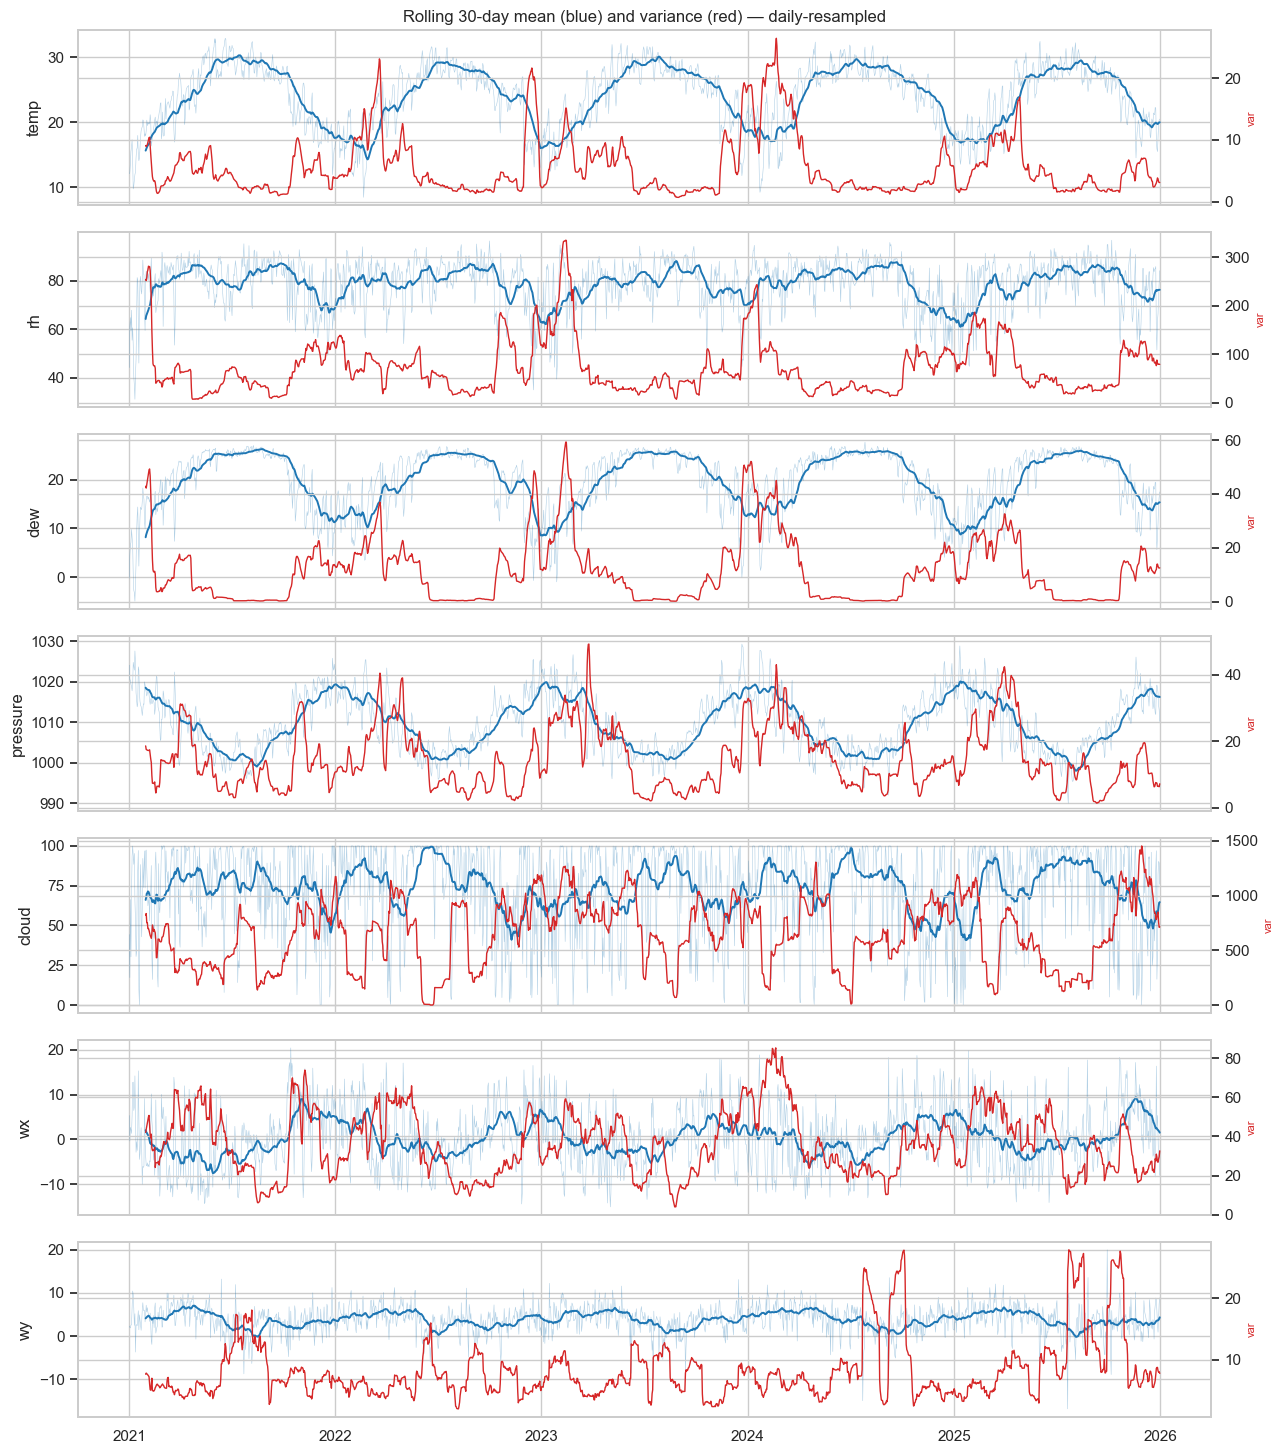

In [10]:
fig, axes = plt.subplots(len(TARGETS), 1, figsize=(13, 2.1 * len(TARGETS)), sharex=True)
for ax, col in zip(axes, TARGETS):
    s = daily[col]
    ax.plot(s.index, s, lw=0.4, alpha=0.35, color="tab:blue")
    ax.plot(s.index, s.rolling(30).mean(), lw=1.4, color="tab:blue", label="30d mean")
    ax2 = ax.twinx()
    ax2.plot(s.index, s.rolling(30).var(), lw=1.0, color="tab:red", label="30d var")
    ax2.set_ylabel("var", color="tab:red", fontsize=8)
    ax.set_ylabel(col)
axes[0].set_title("Rolling 30-day mean (blue) and variance (red) — daily-resampled")
fig.tight_layout()
plt.show()

### 1b. ADF + KPSS (use both — opposite null hypotheses)
- **ADF** null = *has a unit root* → small p ⇒ stationary.
- **KPSS** null = *stationary* → large p ⇒ stationary.

Agreement on "stationary" is strong evidence; disagreement usually flags deterministic
seasonality/trend rather than a stochastic trend.

In [11]:
rows = []
for col in TARGETS:
    s = data[col].dropna()
    adf_p = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    adf_stat = "stationary" if adf_p <= 0.05 else "NON-stat"
    kpss_stat = "stationary" if kpss_p >= 0.05 else "NON-stat"
    if adf_stat == "stationary" and kpss_stat == "stationary":
        verdict = "STATIONARY"
    elif adf_stat == "NON-stat" and kpss_stat == "NON-stat":
        verdict = "non-stationary"
    else:
        verdict = "trend/borderline"
    rows.append([col, round(adf_p, 4), round(kpss_p, 4), adf_stat, kpss_stat, verdict])

pd.DataFrame(rows, columns=["var", "ADF p", "KPSS p", "ADF", "KPSS", "verdict"])

C:\Users\vuthe\AppData\Local\Temp\ipykernel_1692\2180858787.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(s, regression="c", nlags="auto")[1]


C:\Users\vuthe\AppData\Local\Temp\ipykernel_1692\2180858787.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(s, regression="c", nlags="auto")[1]


C:\Users\vuthe\AppData\Local\Temp\ipykernel_1692\2180858787.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(s, regression="c", nlags="auto")[1]


C:\Users\vuthe\AppData\Local\Temp\ipykernel_1692\2180858787.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(s, regression="c", nlags="auto")[1]


,var,ADF p,KPSS p,ADF,KPSS,verdict
0,temp,0.0,0.0486,stationary,NON-stat,trend/borderline
1,rh,0.0,0.1000,stationary,stationary,STATIONARY
2,dew,0.0,0.0994,stationary,stationary,STATIONARY
3,pressure,0.0,0.1000,stationary,stationary,STATIONARY
4,cloud,0.0,0.1000,stationary,stationary,STATIONARY
5,wx,0.0,0.0298,stationary,NON-stat,trend/borderline
6,wy,0.0,0.1000,stationary,stationary,STATIONARY


## 2. ACF & PACF (model-order identification)

- **ACF tails off, PACF cuts off after lag p** ⇒ AR(p) structure.
- A bump near **lag 24** reflects the daily cycle.

Cross-checks the AIC lag order used by the VAR pipeline.

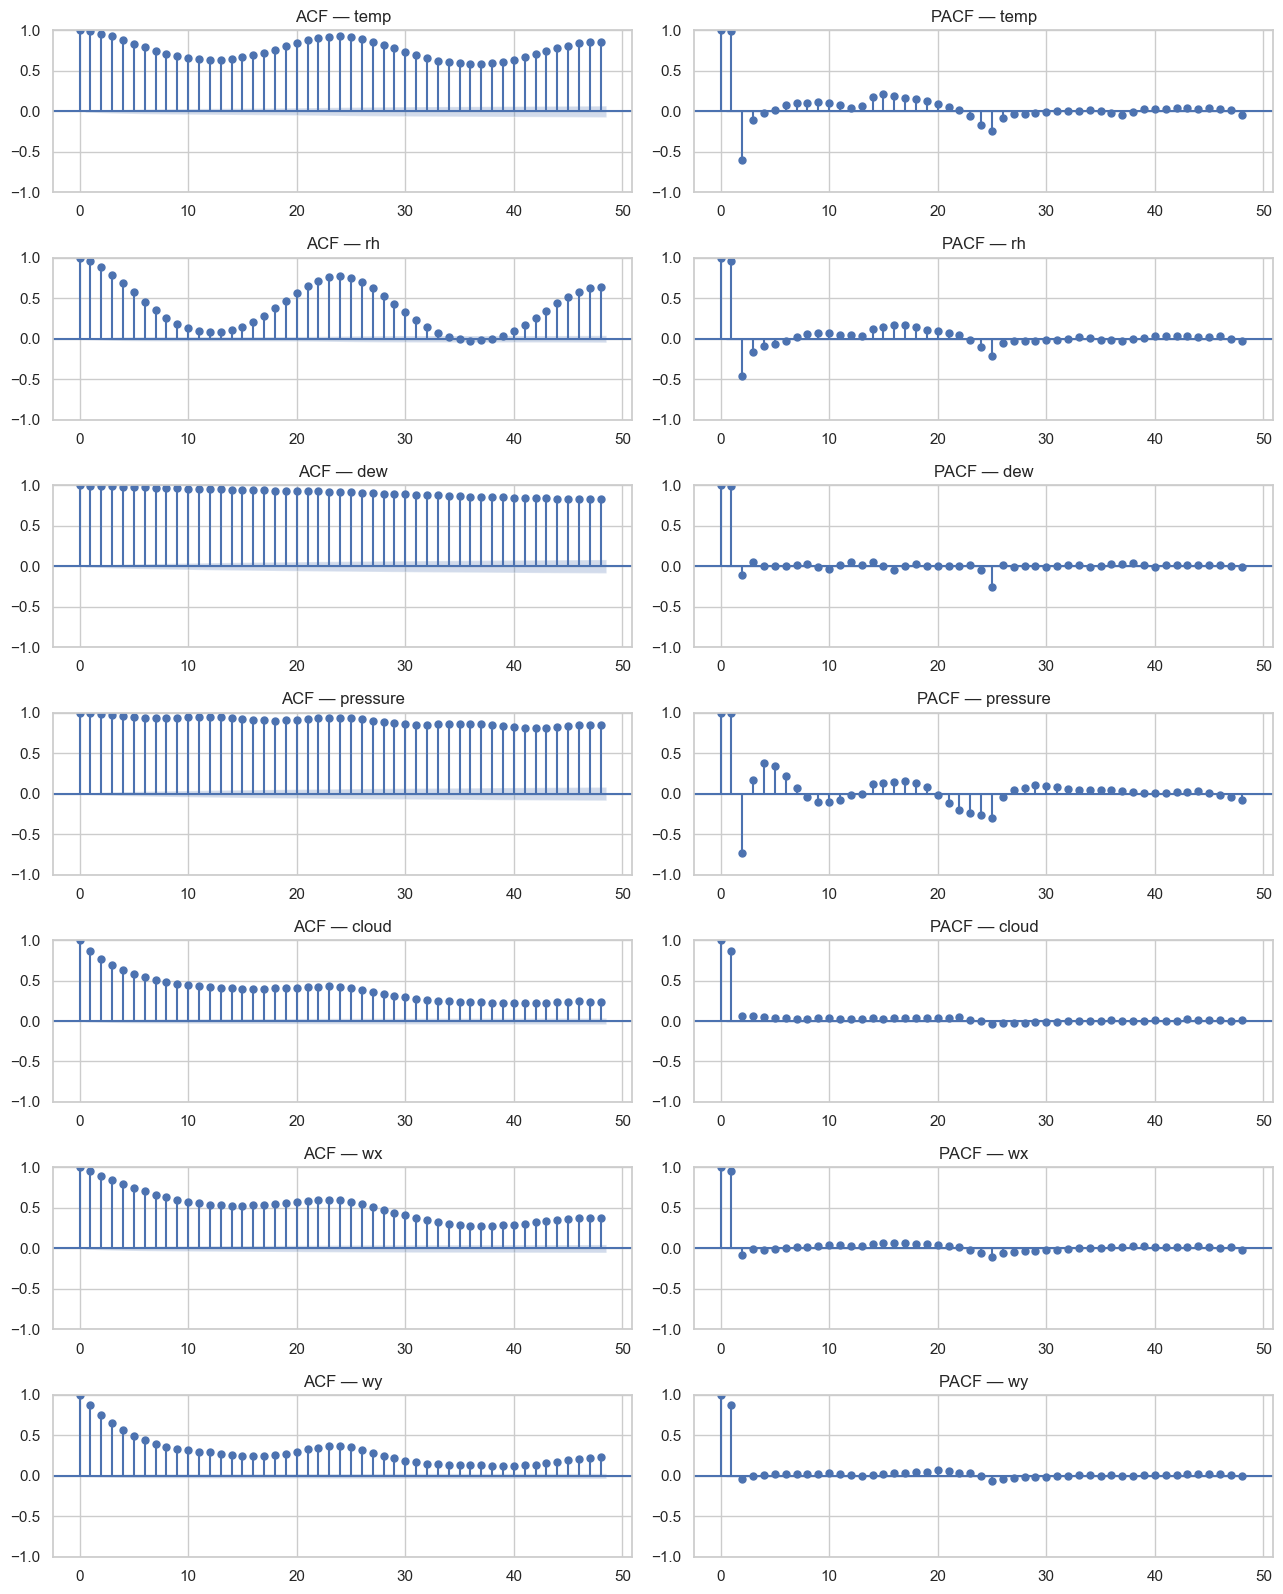

In [12]:
fig, axes = plt.subplots(len(TARGETS), 2, figsize=(13, 2.3 * len(TARGETS)))
for i, col in enumerate(TARGETS):
    plot_acf(data[col], lags=48, ax=axes[i, 0], title=f"ACF — {col}")
    plot_pacf(data[col], lags=48, ax=axes[i, 1], method="ywm", title=f"PACF — {col}")
fig.tight_layout()
plt.show()

## 3. Decomposition (Trend + Seasonal + Residual)

### 3a. Daily cycle (standardized mean by hour-of-day)
Shows which variables have a strong 24-h cycle. (Peaks shifted ~+7h vs local time → timestamps look like **UTC**.)

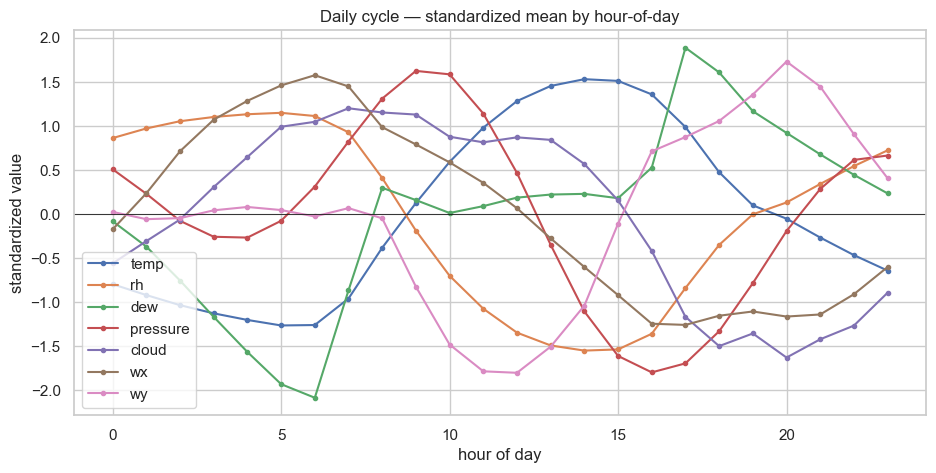

In [13]:
prof = data.groupby(data.index.hour).mean()
profz = (prof - prof.mean()) / prof.std()
ax = profz.plot(figsize=(11, 5), marker=".")
ax.set_title("Daily cycle — standardized mean by hour-of-day")
ax.set_xlabel("hour of day"); ax.set_ylabel("standardized value")
ax.axhline(0, color="k", lw=0.6)
plt.show()

### 3b. Temperature: hour-of-day vs month (how the daily cycle shifts across seasons)

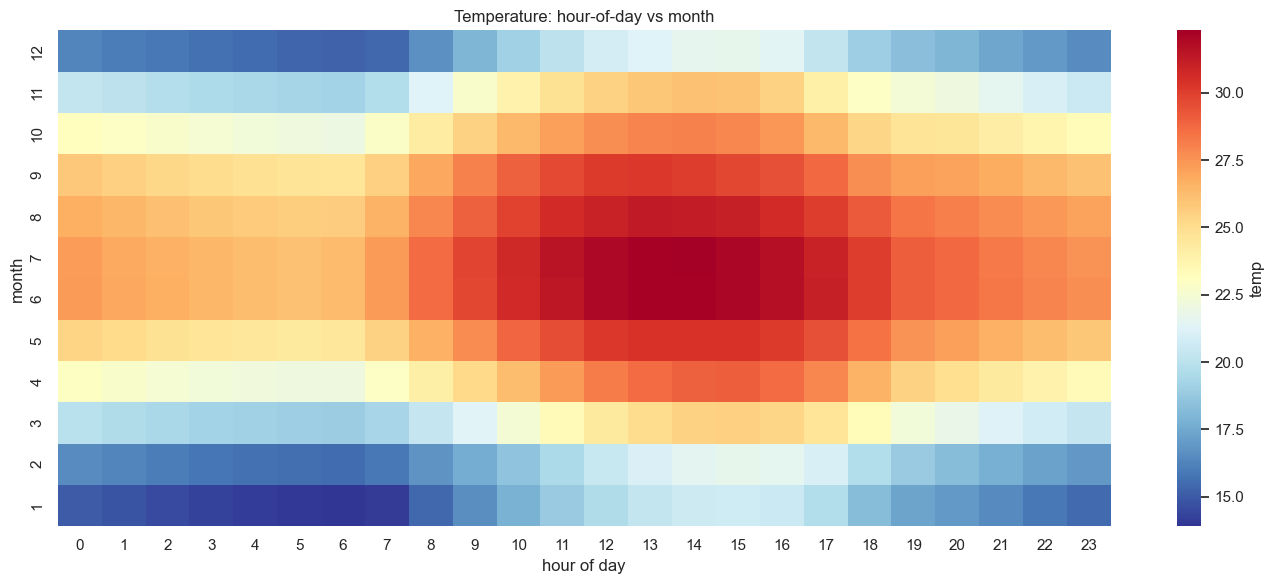

In [14]:
tmp = data[["temp"]].copy()
tmp["hour"] = tmp.index.hour
tmp["month"] = tmp.index.month
pivot = tmp.pivot_table(values="temp", index="month", columns="hour", aggfunc="mean")
plt.figure(figsize=(14, 6))
sns.heatmap(pivot, cmap="RdYlBu_r", cbar_kws={"label": "temp"})
plt.title("Temperature: hour-of-day vs month")
plt.xlabel("hour of day"); plt.ylabel("month")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 3c. Annual decomposition per target (period = 365 days)
Additive model on the daily-resampled series. The **seasonal** panel exposes the annual
cycle; the **trend** panel shows any slow multi-year drift.

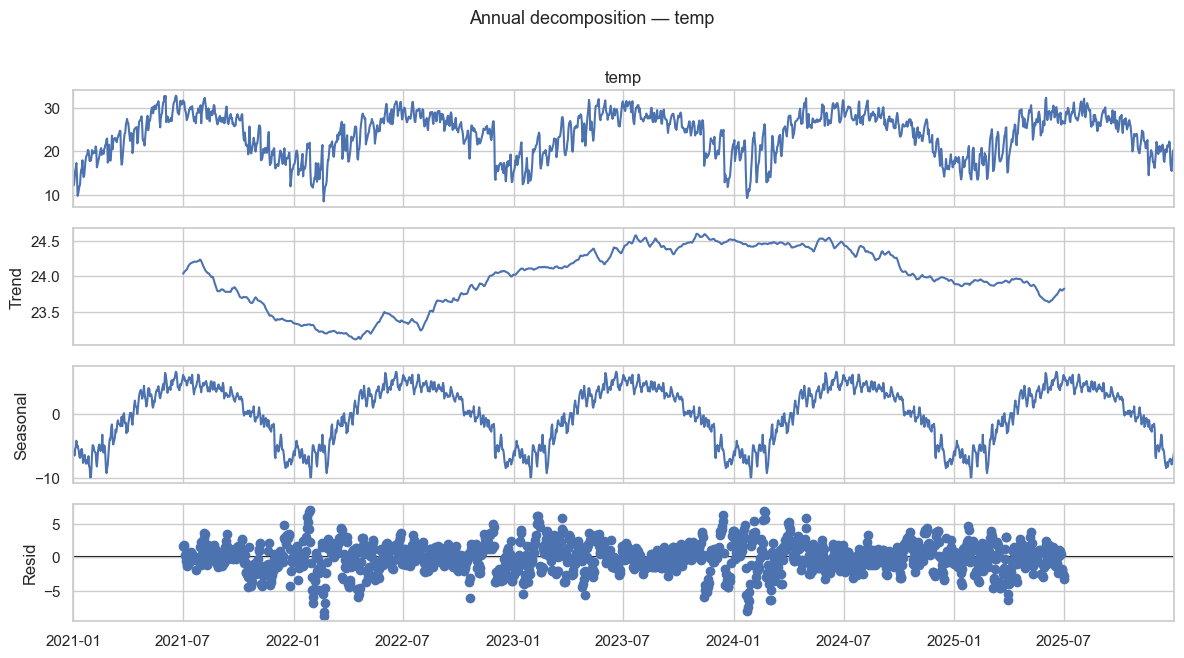

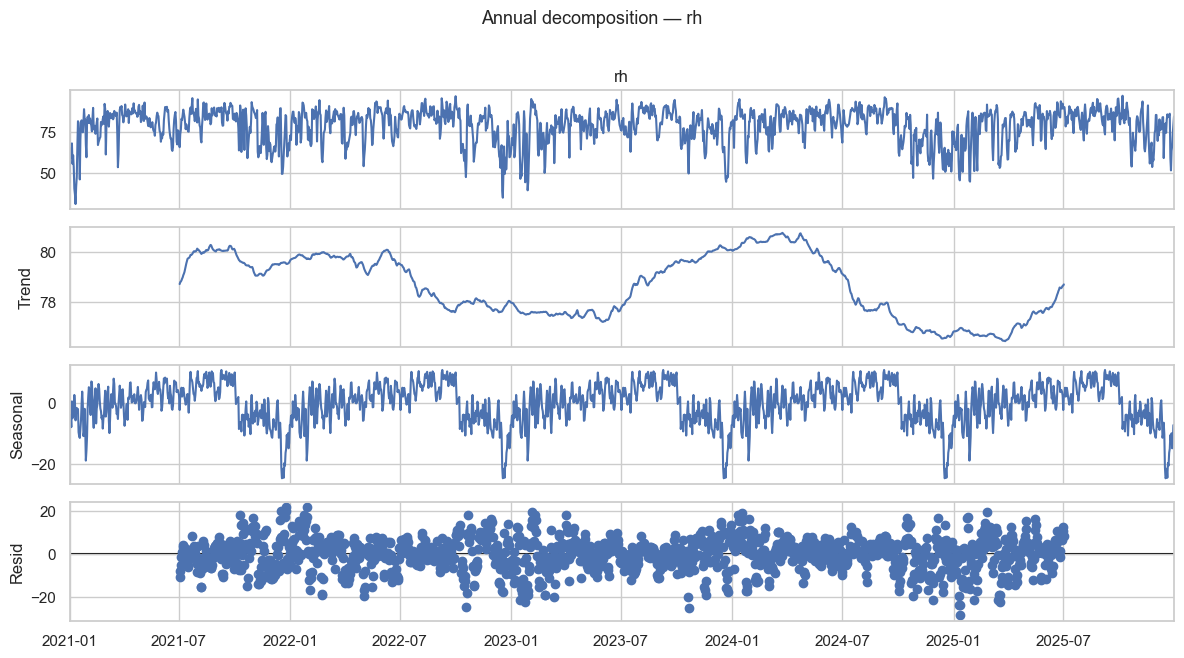

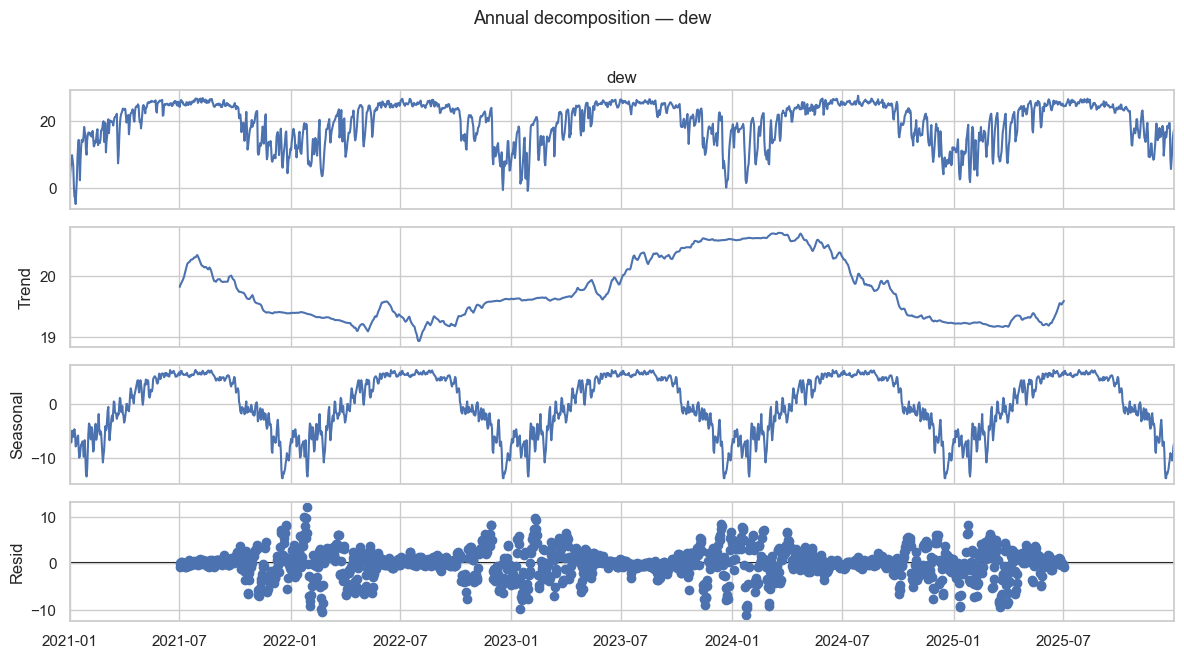

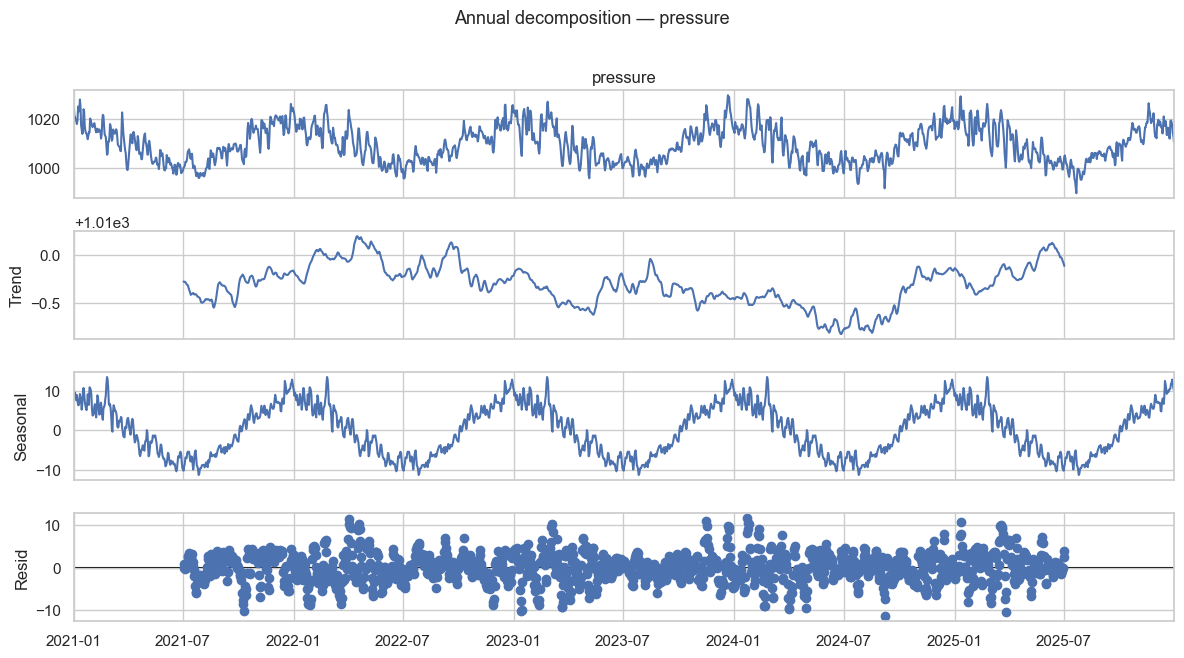

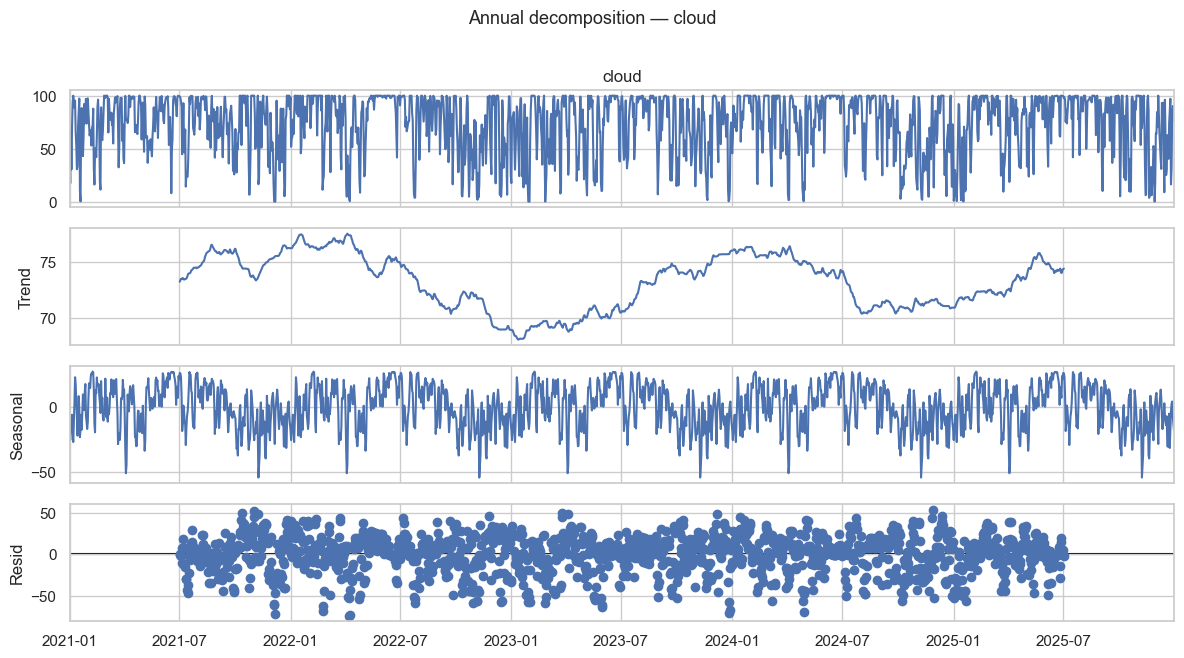

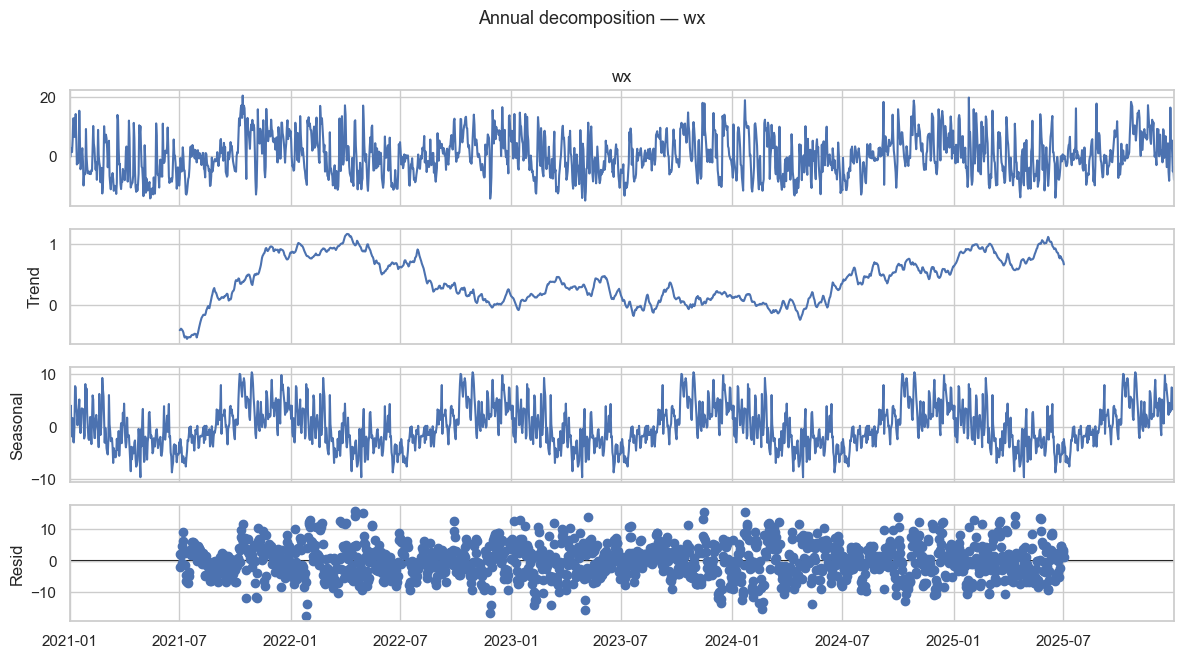

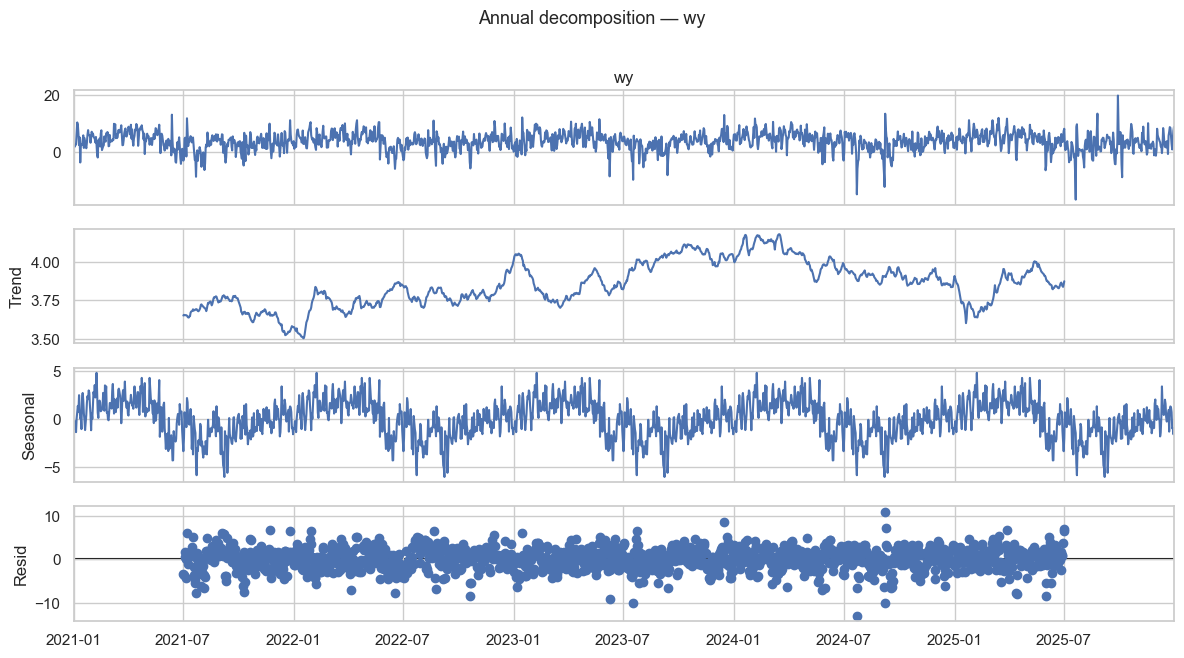

In [15]:
for col in TARGETS:
    res = seasonal_decompose(daily[col].dropna(), model="additive", period=365)
    fig = res.plot()
    fig.set_size_inches(12, 6.5)
    fig.suptitle(f"Annual decomposition — {col}", y=1.01, fontsize=13)
    fig.tight_layout()
    plt.show()

## 4. Lagged cross-correlation (why VAR, not 7 separate models)

If one variable's **past** correlates with another's **present**, a multivariate model (VAR)
can exploit it — something 7 independent AR/ARIMA models cannot.

### 4a. `temp` leading the other variables

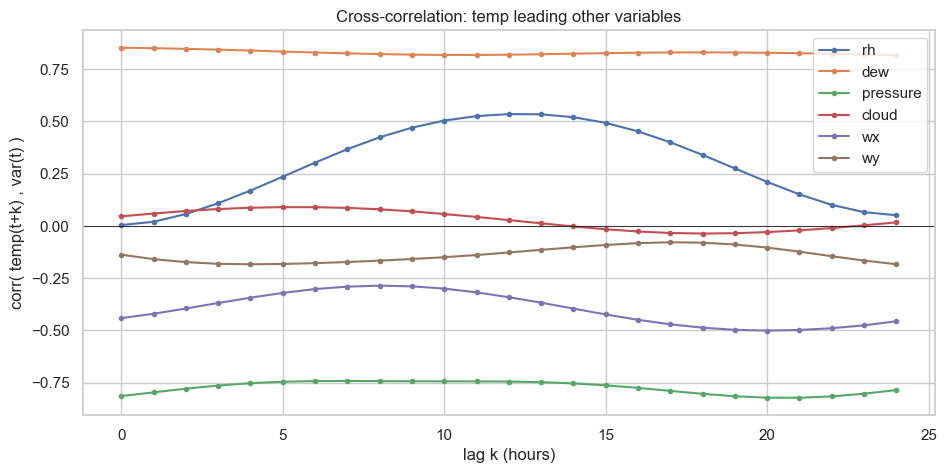

In [16]:
maxlag = 24
ref = "temp"
fig, ax = plt.subplots(figsize=(11, 5))
for col in TARGETS:
    if col == ref:
        continue
    c = ccf(data[ref], data[col])[: maxlag + 1]
    ax.plot(range(maxlag + 1), c, marker=".", label=col)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("lag k (hours)")
ax.set_ylabel(f"corr( {ref}(t+k) , var(t) )")
ax.set_title(f"Cross-correlation: {ref} leading other variables")
ax.legend()
plt.show()

### 4b. Lagged cross-correlation matrix
`corr( row(t), col(t-lag) )` — does each column's recent past help predict each row?
Strong off-diagonal values are the multivariate signal VAR uses.

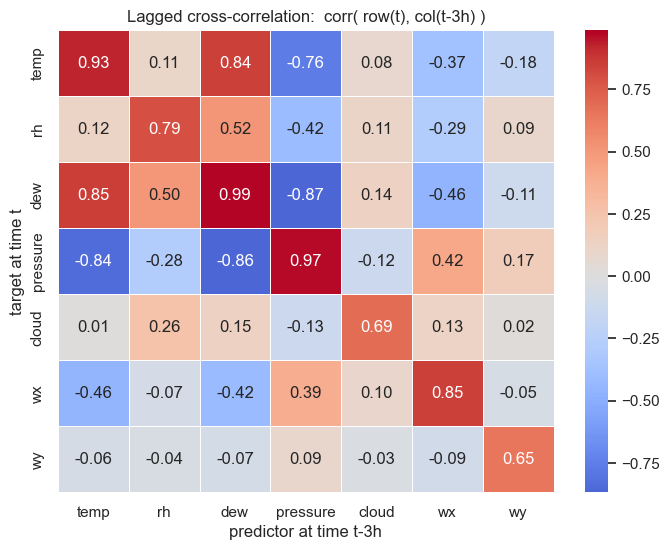

In [17]:
lag = 3  # hours
M = pd.DataFrame(index=TARGETS, columns=TARGETS, dtype=float)
for a in TARGETS:
    for b in TARGETS:
        M.loc[a, b] = np.corrcoef(data[a].values[lag:], data[b].values[:-lag])[0, 1]

plt.figure(figsize=(8, 6))
sns.heatmap(M.astype(float), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title(f"Lagged cross-correlation:  corr( row(t), col(t-{lag}h) )")
plt.ylabel("target at time t"); plt.xlabel(f"predictor at time t-{lag}h")
plt.show()

## Takeaways

- **Stationarity:** ADF + rolling stats indicate no unit root; KPSS borderline cases (e.g. `temp`, `wx`)
  reflect the **annual** cycle, not a stochastic trend → no differencing needed (`d=0`).
- **ACF/PACF:** PACF cutoff after a few lags supports a low base AR order; the lag-24 bump is the daily cycle
  the `VAR(p)` captures through its lags.
- **Decomposition:** strong **daily + annual** seasonality; trends are mild/non-monotonic. The annual cycle
  (period >> lag order) is the part VAR can't model directly — motivates seasonal `exog` terms.
- **Cross-correlation:** clear lagged links between variables justify the **multivariate VAR** over
  independent univariate models.